In [1]:
#| include: false
# Disable tqdm progress bars; this is a hidden cell on the docs page
import os

os.environ["TQDM_DISABLE"] = "1"

# Make a region list plottable on the Swanson map

The Swanson map draws a fixed set of regions, so a value given for a region outside that set is not drawn. This page shows which regions the map holds and how to convert a region list to them. For plotting the values, see [Show one value per region on the Swanson map](plot-on-swanson-flatmap.ipynb).

## The regions on the Swanson map

The regions are the ones in the Swanson mapping, `br.mappings['Swanson']`:

In [2]:
import numpy as np

from iblatlas.plots import plot_swanson_vector
from iblatlas.regions import BrainRegions

br = BrainRegions()
swanson_indices = np.unique(br.mappings['Swanson'])
swanson_acronyms = np.sort(br.acronym[swanson_indices])
swanson_acronyms.size

323

A region's parents and children are not in the set. `VISa` is a Swanson region; its child `VISa2/3` and its parent `PTLp` are not:

In [3]:
for acronym in ('VISa', 'VISa2/3', 'PTLp'):
    print(acronym, np.isin([acronym], swanson_acronyms))

VISa [ True]
VISa2/3 [False]
PTLp [False]


The mapping holds the indices of one hemisphere only. `VISa` has one index per hemisphere, and only the first is in the mapping:

In [4]:
for index in br.acronym2index('VISa')[1][0]:
    print(f'index {index} in the Swanson mapping: {index in swanson_indices}')

index 347 in the Swanson mapping: True
index 1674 in the Swanson mapping: False


## Which values are drawn

A value for a Swanson region is drawn. A value for a region below a Swanson region is not: here `VISa1` and `VISa2/3` are left grey, and only `CA1` and `VPM` are coloured. To show layer values on the map, combine them into one value for `VISa` first, with the mean or whatever summary suits your data.

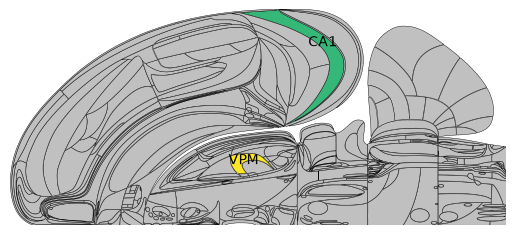

In [5]:
acronyms = ['VISa1', 'VISa2/3', 'CA1', 'VPM']
plot_swanson_vector(acronyms, np.array([1, 2, 3, 4]), annotate=True,
                    annotate_list=acronyms, empty_color='silver', br=br);

A value for a region above Swanson regions colours every Swanson region inside it. `PTLp` contains `VISa` and `VISrl`, and both take its value:

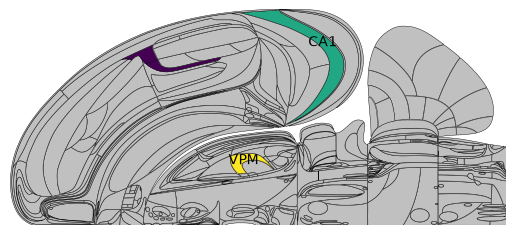

In [6]:
acronyms = ['PTLp', 'CA1', 'VPM']
plot_swanson_vector(acronyms, np.array([1.5, 3, 4]), annotate=True,
                    annotate_list=acronyms, empty_color='silver', br=br);

When a region and one of the Swanson regions inside it both have values, the inner region shows its own value and the rest of the outer region shows the outer value:

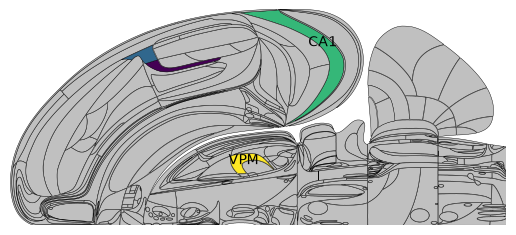

In [7]:
acronyms = ['PTLp', 'VISrl', 'CA1', 'VPM']
plot_swanson_vector(acronyms, np.array([1, 2, 3, 4]), annotate=True,
                    annotate_list=acronyms, empty_color='silver', br=br);

The same applies at any level, for example a whole top-level region with one region inside it:

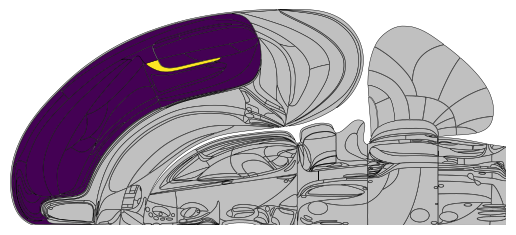

In [8]:
acronyms = ['Isocortex', 'VISa']
plot_swanson_vector(acronyms, np.array([1, 2]), annotate=True,
                    annotate_list=acronyms, empty_color='silver', br=br);

## Convert a region list to Swanson regions

`br.acronym2acronym` with `mapping='Swanson'` returns the Swanson region that contains each acronym. See [Brain region mappings](../explanation/brain-region-mappings.qmd).

In [9]:
br.acronym2acronym(['MDm', 'VISa2/3', 'CA1'], mapping='Swanson')

array(['MD', 'VISa', 'CA1'], dtype=object)